# 02 · Smearing in energia e taratura del modello fotostatistico

La simulazione non genera fotoni ottici: l'energia depositata in ogni barra è presa direttamente dal volume Geant4 e poi "sporcata" con una gaussiana che emula le fluttuazioni della lettura SiPM. Il parametro (FWHM relativa) era stato tarato a **0.22** perché le distribuzioni simulate dell'offset coincidessero con quelle del test beam 2018.

Per lo scan sulle dimensioni delle barre questo modello (`CONSTANT`, σ_E/E fisso) non basta: barre più sottili depositano meno energia, raccolgono meno fotoelettroni e hanno una risoluzione relativa peggiore. Il modello `PHOTOSTAT` assume σ_E/E ∝ 1/√E:

* `CONSTANT`: σ_E = s · E / 2.355
* `PHOTOSTAT`: σ_E = s · √(E · E_ref) / 2.355, con E_ref = 7 MeV (≈ energia media per barra colpita nel test beam)

Il parametro s di `PHOTOSTAT` si tara imponendo che, nel setup del test beam, dia le **stesse distribuzioni dell'offset** di `CONSTANT` 0.22 (cioè le stesse dei dati).

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
import sithplot as sp
sp.setup()
import sith_reco as sr
R = sp.RUNS
geom = sr.Geometry()
pat = lambda d: str(R / d / "output" / "*MeV_t*-{run}.root")
calib = json.load(open(R / "scan_bars" / "calib" / "calibration.json"))
S_PHOT, E_REF = calib["photostat_smear"], 7.0
print(f"PHOTOSTAT tarato: s = {S_PHOT:.4f} (E_ref = {E_REF} MeV)")

PHOTOSTAT tarato: s = 0.1799 (E_ref = 7.0 MeV)


## 1. Quanta energia vede una barra

Depositi Geant4 *senza* smearing (run `const_0.0`) nelle quattro barre della coppia usata per l'offset, su tutti gli step del test beam. La somma sulle due barre di una coppia è circa costante (≈ altezza × dE/dx); il singolo deposito va da quasi zero (traccia vicino al vertice) al massimo.

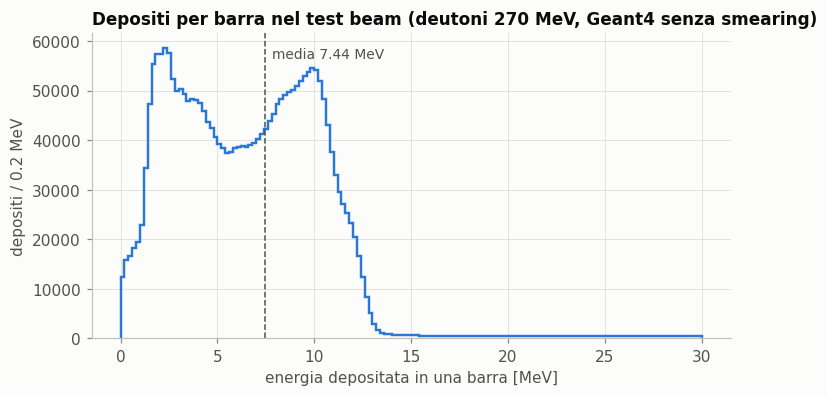

In [2]:
E = []
for k in range(7):
    F, B, _ = sr.load(sr.run_files(pat("const_0.0"), k), geom, extra=())
    for a in (F[:, 3], F[:, 11], B[:, 3], B[:, 11]):
        E.append(a[np.isfinite(a)])
E = np.concatenate(E)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
sp.hist_line(ax, E, 150, (0, 30), sp.SERIES[0])
ax.axvline(E.mean(), color=sp.INK2, lw=1, ls="--")
ax.annotate(f"media {E.mean():.2f} MeV", (E.mean(), ax.get_ylim()[1] * 0.92), xytext=(5, 0),
            textcoords="offset points", color=sp.INK2, fontsize=9)
ax.set(xlabel="energia depositata in una barra [MeV]", ylabel="depositi / 0.2 MeV",
       title="Depositi per barra nel test beam (deutoni 270 MeV, Geant4 senza smearing)")
plt.show()

## 2. I due modelli a confronto

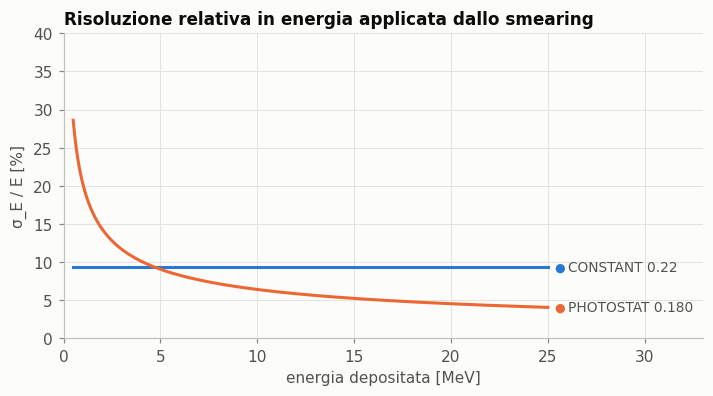

In [3]:
e = np.linspace(0.5, 25, 300)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(e, np.full_like(e, 100 * 0.22 / 2.355), color=sp.SERIES[0])
ax.plot(e, 100 * S_PHOT / 2.355 * np.sqrt(E_REF / e), color=sp.SERIES[1])
sp.end_label(ax, 25, 100 * 0.22 / 2.355, "CONSTANT 0.22", sp.SERIES[0])
sp.end_label(ax, 25, 100 * S_PHOT / 2.355 * np.sqrt(E_REF / 25), f"PHOTOSTAT {S_PHOT:.3f}", sp.SERIES[1])
ax.set(xlim=(0, 33), ylim=(0, 40), xlabel="energia depositata [MeV]", ylabel="σ_E / E [%]",
       title="Risoluzione relativa in energia applicata dallo smearing")
plt.show()

## 3. Risoluzione del test beam in funzione dello smearing

Ogni punto è uno scan completo del test beam (7 step × 100k eventi, stessi seed), analizzato come nell'articolo. Lo smearing 0 dà il contributo della sola fisica (fluttuazioni di Landau, raggi δ, scattering multiplo, non linearità della ricostruzione).

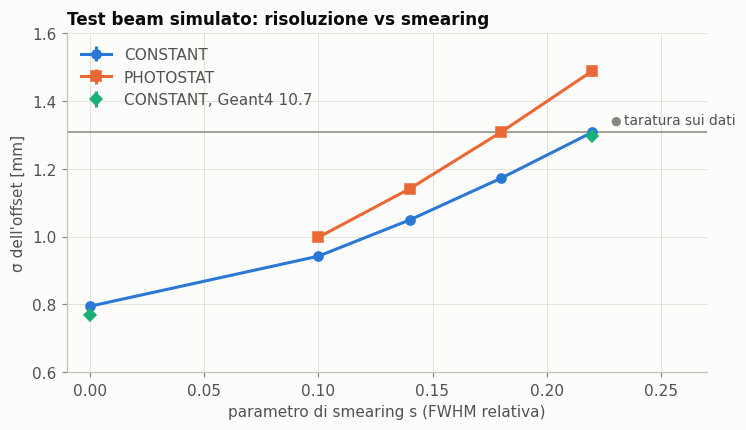

,modello,smearing,σ offset [mm],errore [mm]
0,CONSTANT,0.00,0.794670,0.002291
1,CONSTANT,0.10,0.942387,0.002964
2,CONSTANT,0.14,1.049422,0.003797
3,CONSTANT,0.18,1.172484,0.005340
4,CONSTANT,0.22,1.308431,0.008261
5,PHOTOSTAT,0.10,0.998155,0.003333
6,PHOTOSTAT,0.14,1.141480,0.004826
7,PHOTOSTAT,0.18,1.308470,0.008143
8,PHOTOSTAT,0.22,1.489447,0.015853
9,"CONSTANT, Geant4 10.7",0.00,0.767902,0.002203


In [4]:
def tb(d):
    r = sr.analyse_tb(pat(d), 7, geom)
    return r["sigma_mm_mean"], r["sigma_mm_err_mean"]

rows = []
for s in ("0.0", "0.10", "0.14", "0.18", "0.22"):
    rows.append(("CONSTANT", float(s), *tb(f"const_{s}")))
for s in ("0.10", "0.14", "0.18", "0.22"):
    rows.append(("PHOTOSTAT", float(s), *tb(f"phot_{s}")))
for s in ("0.0", "0.22"):
    rows.append(("CONSTANT, Geant4 10.7", float(s), *tb(f"g4107_{s}")))
scan = pd.DataFrame(rows, columns=["modello", "smearing", "σ offset [mm]", "errore [mm]"])
target = scan.query("modello == 'CONSTANT' and smearing == 0.22")["σ offset [mm]"].item()

fig, ax = plt.subplots(figsize=(7.5, 4))
styles = {"CONSTANT": (sp.SERIES[0], "o-"), "PHOTOSTAT": (sp.SERIES[1], "s-"), "CONSTANT, Geant4 10.7": (sp.SERIES[2], "D")}
for m, g in scan.groupby("modello", sort=False):
    c, f = styles[m]
    ax.errorbar(g.smearing, g["σ offset [mm]"], g["errore [mm]"], fmt=f, color=c, label=m, ms=6)
ax.axhline(target, color=sp.MUTED, lw=1)
sp.end_label(ax, 0.225, target, "taratura sui dati", sp.MUTED, dy=8)
ax.set(xlim=(-0.01, 0.27), ylim=(0.6, 1.6), xlabel="parametro di smearing s (FWHM relativa)",
       ylabel="σ dell'offset [mm]", title="Test beam simulato: risoluzione vs smearing")
ax.legend(loc="upper left")
plt.show()
scan

## 4. Taratura di `PHOTOSTAT`

Run dedicati da 7 × 200k eventi con **gli stessi seed** per tutti i valori di s e per il riferimento `CONSTANT` 0.22: la parte Geant4 degli eventi è identica, cambia solo lo smearing, e la differenza tra i punti è poco rumorosa.

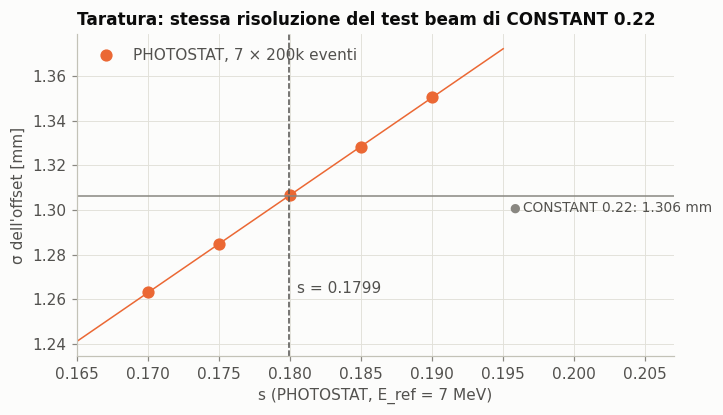

In [5]:
s = np.array(calib["smear"]); y = np.array(calib["sigma_mm"])
xx = np.linspace(s.min() - 0.005, s.max() + 0.005, 50)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(s, y, "o", color=sp.SERIES[1], ms=7, label="PHOTOSTAT, 7 × 200k eventi")
ax.plot(xx, calib["slope"] * xx + calib["intercept"], color=sp.SERIES[1], lw=1)
ax.axhline(calib["target_mm"], color=sp.MUTED, lw=1)
ax.axvline(S_PHOT, color=sp.INK2, lw=1, ls="--")
sp.end_label(ax, xx[-1], calib["target_mm"], f"CONSTANT 0.22: {calib['target_mm']:.3f} mm", sp.MUTED, dy=-8)
ax.annotate(f"s = {S_PHOT:.4f}", (S_PHOT, y.min()), xytext=(5, 0), textcoords="offset points", color=sp.INK2)
ax.set(xlim=(xx[0], xx[-1] + 0.012), xlabel="s (PHOTOSTAT, E_ref = 7 MeV)", ylabel="σ dell'offset [mm]",
       title="Taratura: stessa risoluzione del test beam di CONSTANT 0.22")
ax.legend(loc="upper left")
plt.show()

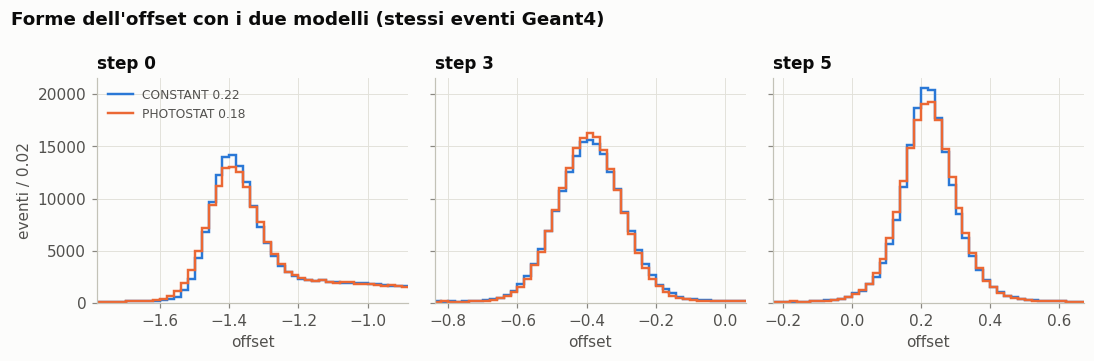

In [6]:
# confronto delle forme: CONSTANT 0.22 vs il PHOTOSTAT di griglia più vicino alla taratura
near = min(calib["smear"], key=lambda v: abs(v - S_PHOT))
def offs(d):
    out = []
    for k in range(7):
        F, B, _ = sr.load(sr.run_files(str(R / "scan_bars" / "calib" / d / "output" / "*MeV_t*-{run}.root"), k), geom, extra=())
        qF, rF, eF = sr.select_pairs(F, 7); qB, rB, eB = sr.select_pairs(B, 7)
        m = (qF == 3) & (rF == 11) & (qB >= 0)
        out.append(eF[m] - eB[m])
    return out
oc, op = offs("const_0.22"), offs(f"phot_{near}")
fig, axs = plt.subplots(1, 3, figsize=(10, 3.3), sharey=True)
for ax, k in zip(axs, (0, 3, 5)):
    sp.hist_line(ax, oc[k], 200, (-2, 2), sp.SERIES[0], label="CONSTANT 0.22")
    sp.hist_line(ax, op[k], 200, (-2, 2), sp.SERIES[1], label=f"PHOTOSTAT {near}")
    mu = np.median(oc[k]); ax.set(xlim=(mu - 0.45, mu + 0.45), title=f"step {k}", xlabel="offset")
axs[0].set_ylabel("eventi / 0.02"); axs[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Forme dell'offset con i due modelli (stessi eventi Geant4)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Lettura.**

* Senza smearing Geant4 dà già ~0.8 mm (larghezza dell'offset): lo smearing 0.22 porta a ~1.31 mm e riproduce i dati.
* `PHOTOSTAT` con s ≈ 0.18 (E_ref = 7 MeV) dà la stessa larghezza e forme molto simili: per energie sopra E_ref la risoluzione è un po' migliore di `CONSTANT`, sotto è peggiore (code dei depositi piccoli vicino ai vertici).
* Nello scan sulle barre il modello tarato fa la differenza vera: con barre sottili l'energia scende e la risoluzione relativa peggiora come 1/√E, cosa che `CONSTANT` ignora.

*Limite noto:* il modello assume la stessa resa in fotoelettroni per MeV per tutte le geometrie. In realtà barre di sezione più piccola hanno una frazione maggiore della faccia coperta dal SiPM (6×6 mm²) e raccolgono più luce per MeV: questo effetto, favorevole alle barre piccole, non è incluso.